# C — Khảo sát tổ hợp Front-End trên V1: 8 cấu hình × 3 seed

**Tiếp nối B:** từ các phép OFAT seed 42, C mở rộng thành ma trận 2×2×2 trên **V1 cố định**: bật/tắt pre-emphasis (`α=0,97/0`), Mel (`64/40`) và FFT (`1024/2048`). Với seed 42,43,44, tổng cộng **24 checkpoint FP32**. Đây là vòng đánh giá tương tác và biến thiên, không sửa lại thí nghiệm OFAT đã thực hiện.

**Mục đích:** 
- So sánh tổ hợp bằng Validation và chỉ số theo lớp
- Ghi nhận giới hạn một seed
- Chọn cấu hình ứng viên đưa sang thử lượng tử. 

**C4 (α=0, Mel40, FFT2048) được ưu tiên sau tổng hợp bằng chứng**, không phải giả định ban đầu để xếp hạng các tổ hợp.

**Luồng kế tiếp:** từ kết quả C, chuyển sang **D — Quantization** để đối chiếu PTQ/QAT và khả năng duy trì chất lượng khi chuyển sang INT8 trước khi quyết định phương án triển khai. Các kiểm chứng kiến trúc và phần cứng được trình bày riêng ở bước tổng kết sau đó.

## 0. Ma trận thí nghiệm 24 checkpoint và cấu hình đường dẫn

| Nhóm | Tên trong báo cáo | Pre-emphasis | Mel | FFT | Seed |
|---|---|---:|---:|---:|---|
| Baseline | F0 | 0,97 | 64 | 1024 | 42,43,44 |
| Đơn lẻ | pre_0 | 0 | 64 | 1024 | 42,43,44 |
| Đơn lẻ | mel_40 | 0,97 | 40 | 1024 | 42,43,44 |
| Đơn lẻ | fft_2048 | 0,97 | 64 | 2048 | 42,43,44 |
| Combo | C1: pre0+mel40 | 0 | 40 | 1024 | 42,43,44 |
| Combo | C2: pre0+fft2048 | 0 | 64 | 2048 | 42,43,44 |
| Combo | C3: mel40+fft2048 | 0,97 | 40 | 2048 | 42,43,44 |
| Combo | C4: pre0+mel40+fft2048 | 0 | 40 | 2048 | 42,43,44 |

Các tham số khác giữ nguyên F0 (16 kHz, mono 5 s, Butterworth bậc 5, 100-2000 Hz, hop=625, Slaney) và kiến trúc `V1`. **Tên variant thực tế lấy từ `experiment_plan.csv` bằng bộ tham số**, không đoán đường dẫn `C2/C3/C4` khi b đặt tên khác.

- Mở notebook **trong thư mục `Frontend_Benchmarking`**, hoặc điền biến `FRONTEND_ROOT_OVERRIDE` / môi trường `NCKH_FRONTEND_DIR`.
- Nếu chưa đủ checkpoint, chạy các runner C rồi đồng bộ summary trước khi mở notebook.
- Notebook chỉ đọc hai nguồn chuẩn `results/val_summary.csv` và `results/test_summary.csv`, không inference và không tạo thêm bản sao summary.

In [1]:
from pathlib import Path 
import os, sys, json, hashlib
os.environ.setdefault('TF_ENABLE_ONEDNN_OPTS','0')  # align Phase2 before TensorFlow import
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# === Chỉ chỉnh ô này khi Notebook ở ngoài phạm vi ===
FRONTEND_ROOT_OVERRIDE = ""   # VD: r"D:\NCKH_2026\...\Frontend_Benchmarking"

SEEDS = (42,43,44)
EXPECTED = {
    'F0': (0.97,64,1024),
    'pre_0': (0.0,64,1024),
    'mel_40': (0.97,40,1024),
    'fft_2048': (0.97,64,2048),
    'C1': (0.0,40,1024),
    'C2': (0.0,64,2048),
    'C3': (0.97,40,2048),
    'C4': (0.0,40,2048),
}
PREFERRED_IDS = {
    'F0':'F0','pre_0':'pre_0','mel_40':'mel_40','fft_2048':'fft_2048',
    'C1':'combo_pre0_mel40','C2':'combo_pre0_fft2048',
    'C3':'combo_mel40_fft2048','C4':'combo_pre0_mel40_fft2048',
}
RECIPE = 'V1_phase2_exact_float64_raw_float32_after_normalize_v2'
N_VAL, N_TEST = 154, 159


def find_root():
    bases=[]
    if FRONTEND_ROOT_OVERRIDE: bases.append(Path(FRONTEND_ROOT_OVERRIDE).expanduser())
    for key in ('FRONTEND_BENCHMARK_ROOT','NCKH_FRONTEND_DIR'):
        if os.environ.get(key): bases.append(Path(os.environ[key]).expanduser())
    cur=Path.cwd().resolve(); bases += [cur,*cur.parents]
    for p in bases:
        for d in (p, p/'Frontend_Benchmarking',p/'Experiments_Benchmarking'/'Patient_Node'/'Frontend_Benchmarking'):
            if (d/'frontend_core.py').is_file() and (d/'results'/'experiment_plan.csv').is_file():return d.resolve()
    return None

ROOT = find_root()
VAL_SUMMARY_PATH = (ROOT/'results'/'val_summary.csv') if ROOT else None
TEST_SUMMARY_PATH = (ROOT/'results'/'test_summary.csv') if ROOT else None
print('Frontend root:', ROOT or 'CHƯA TÌM THẤY')
print('Validation summary:', VAL_SUMMARY_PATH)
print('Test summary      :', TEST_SUMMARY_PATH)
print('Chế độ notebook   : chỉ đọc và phân tích 24 checkpoint đã hoàn tất')

Frontend root: D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchmarking\Patient_Node\Frontend_Benchmarking
Validation summary: D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchmarking\Patient_Node\Frontend_Benchmarking\results\val_summary.csv
Test summary      : D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchmarking\Patient_Node\Frontend_Benchmarking\results\test_summary.csv
Chế độ notebook   : chỉ đọc và phân tích 24 checkpoint đã hoàn tất


## 1. Kiểm tra danh sách 24 checkpoint — chưa đủ thì hiện PENDING

Kiểm tra danh sách ở **Validation trước**, chỉ sử dụng checkpoint đã train và có metadata. Các `C2/C3/C4` cần đăng ký vào `experiment_plan.csv` với đúng `n_fft/n_mels/pre_emphasis`

Nếu thiếu hoặc có hai cấu hình trùng bộ ba, notebook dừng để B chỉnh plan, không dùng nhầm model.

In [2]:
plan_map={}
fc=None
if ROOT:
    if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
    import frontend_core as fc
    plan=pd.read_csv(ROOT/'results'/'experiment_plan.csv',encoding='utf-8-sig')
    required={'variant_id','pre_emphasis','n_mels','n_fft','config_sha256'}
    assert required.issubset(plan.columns), f'experiment_plan.csv thiếu {sorted(required-set(plan.columns))}'
    for short,(pre,mel,fft) in EXPECTED.items():
        variant_id=PREFERRED_IDS[short]
        matched=plan[plan.variant_id.astype(str).eq(variant_id)]
        if len(matched)!=1:
            raise ValueError(f'{short}: cần đúng 1 variant_id={variant_id} trong experiment_plan.csv, hiện tìm được {len(matched)}')
        row=matched.iloc[0].to_dict()
        actual=(float(row['pre_emphasis']),int(row['n_mels']),int(row['n_fft']))
        expected=(float(pre),int(mel),int(fft))
        if not (np.isclose(actual[0],expected[0]) and actual[1:]==expected[1:]):
            raise ValueError(f'{short}/{variant_id}: tham số plan {actual} khác EXPECTED {expected}')
        # Check config vs generated hash; reject mismatched recipe/plan
        cfg=fc.load_config(row)
        assert fc.digest(cfg)==row['config_sha256'], f'{short}: config hash mismatch'
        assert cfg.filter_order==5 and cfg.low_cut_hz==100 and cfg.high_cut_hz==2000 and cfg.hop_length==625
        plan_map[short]=row
else:
    print('Không có repo: dùng tên variant dự kiến; chưa thể nghiệm thu config hash.')

VARIANT_IDS={k:(v['variant_id'] if k in plan_map else PREFERRED_IDS[k]) for k,v in plan_map.items()}
for k in EXPECTED:
    VARIANT_IDS.setdefault(k,PREFERRED_IDS[k])
registry=pd.DataFrame([{
    'cau_hinh':k,'variant_id':VARIANT_IDS[k], 'seed':s,
    'trial_id':f'{VARIANT_IDS[k]}__V1__s{s}',
    'Pre':pre,'Mel':mel,'FFT':fft,
    'nhom':'Combo' if k[0]=='C' else 'Baseline/đơn lẻ',
} for k,(pre,mel,fft) in EXPECTED.items() for s in SEEDS])
assert len(registry)==24 and registry.trial_id.is_unique
registry['checkpoint'] = registry.trial_id.map(lambda t:(ROOT/'artifacts'/'models'/t/'Model_Asthma.keras').is_file() if ROOT else False)
registry['metadata'] = registry.trial_id.map(lambda t:(ROOT/'artifacts'/'models'/t/'training_metadata.json').is_file() if ROOT else False)
display(registry[['cau_hinh','variant_id','seed','Pre','Mel','FFT','checkpoint','metadata']])
print('Checkpoint có file:',int(registry.checkpoint.sum()),'/24; thiếu:',registry.loc[~registry.checkpoint,'trial_id'].tolist())

,cau_hinh,variant_id,seed,Pre,Mel,FFT,checkpoint,metadata
0,F0,F0,42,0.97,64,1024,True,True
1,F0,F0,43,0.97,64,1024,True,True
2,F0,F0,44,0.97,64,1024,True,True
3,pre_0,pre_0,42,0.00,64,1024,True,True
4,pre_0,pre_0,43,0.00,64,1024,True,True
5,pre_0,pre_0,44,0.00,64,1024,True,True
6,mel_40,mel_40,42,0.97,40,1024,True,True
7,mel_40,mel_40,43,0.97,40,1024,True,True
8,mel_40,mel_40,44,0.97,40,1024,True,True
9,fft_2048,fft_2048,42,0.97,64,2048,True,True


Checkpoint có file: 24 /24; thiếu: []


## 2. Validation (154 WAV) — so sánh 8×3

Ưu tiên **`artifacts/models/<trial_id>/val_predictions.csv`** để tính lại chỉ số theo đúng từng WAV. Nếu chỉ có hồ sơ D lịch sử, bảng đó sẽ được dùng để trình bày **15 checkpoint cũ**; không bao giờ tự tạo số liệu cho 9 checkpoint mới.

Notebook chỉ phân tích các file do pipeline sinh. Nếu thiếu Validation, hãy chạy `04_Evaluate.py --split val`; kết quả sẽ cập nhật trực tiếp `results/val_summary.csv`. Không inference bên trong notebook.

In [3]:
# Notebook không tự inference hoặc tạo output phụ.
print('Validation được đọc trực tiếp từ results/val_summary.csv và val_predictions.csv.')
print('Nếu thiếu/stale, chạy 04_Evaluate.py hoặc runner C bên ngoài notebook.')

Validation được đọc trực tiếp từ results/val_summary.csv và val_predictions.csv.
Nếu thiếu/stale, chạy 04_Evaluate.py hoặc runner C bên ngoài notebook.


Pipeline summary: đủ 24 checkpoint và SHA provenance hợp lệ.


seed,42,43,44
cau_hinh,,,
F0,94.16,97.40,100.00
pre_0,96.10,96.10,99.35
mel_40,98.05,96.10,95.45
fft_2048,96.75,96.75,97.40
C1,96.75,98.70,99.35
C2,97.40,98.05,96.75
C3,96.10,97.40,98.05
C4,97.40,98.05,98.70


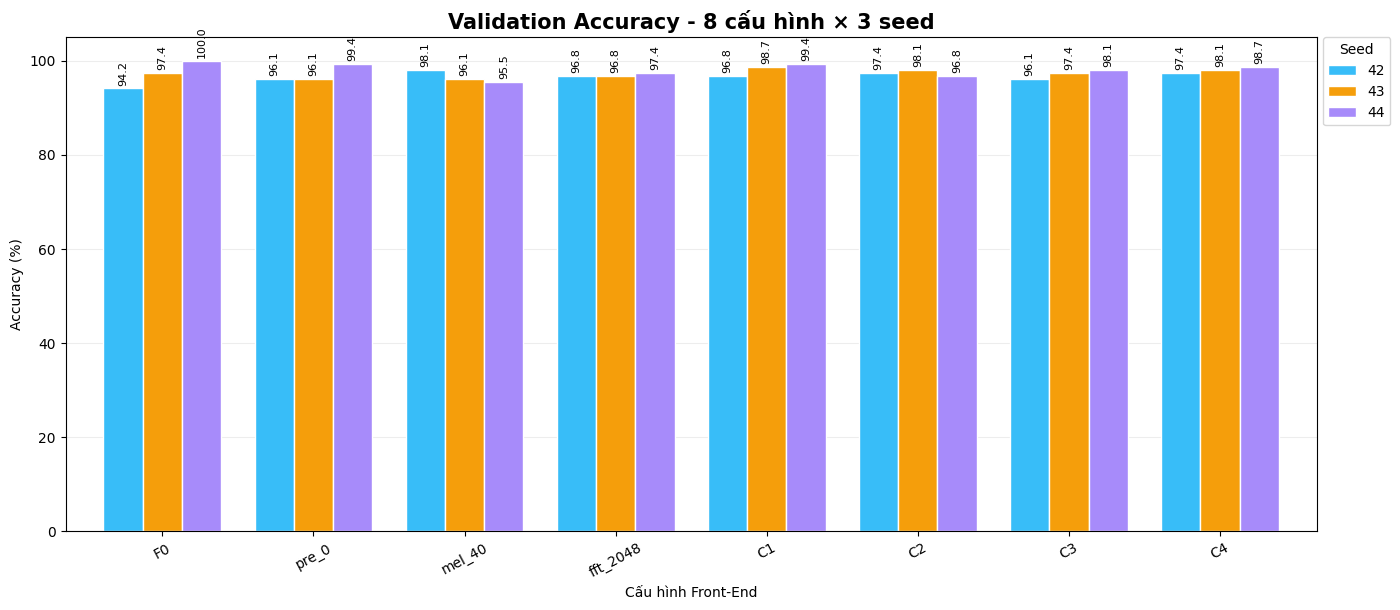

Validation có số liệu: 24 /24 | còn thiếu: []


In [4]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix, log_loss

def calculate_metrics(df):
    y=df.true_label.to_numpy(dtype=int); prob=df.p_non_asthma.to_numpy(dtype=float)
    pred=(prob>=0.5).astype(int)
    if len(y)!=len(set(df.file)) or not np.isfinite(prob).all() or np.any((prob<0)|(prob>1)):
        raise ValueError('WAV trùng / xác suất không hợp lệ')
    if (pred!=df.predicted_label.to_numpy(int)).any():raise ValueError('predicted_label và sigmoid không khớp')
    a=confusion_matrix(y,pred,labels=[0,1]); n0,n1=a.sum(axis=1)
    return dict(accuracy=float(accuracy_score(y,pred)),
        macro_f1=float(f1_score(y,pred,average='macro',labels=[0,1],zero_division=0)),
        balanced_accuracy=float(balanced_accuracy_score(y,pred)),
        asthma_recall=float(a[0,0]/n0),asthma_fn=int(a[0,1]),
        non_asthma_fp=int(a[1,0]),asthma_count=int(n0),non_asthma_count=int(n1),
        log_loss=float(log_loss(y,np.clip(prob,1e-7,1-1e-7),labels=[0,1])))

def standard_prediction_frame(path,tid,n,split):
    p=pd.read_csv(path,encoding='utf-8-sig')
    needed={'file','true_label','p_non_asthma','predicted_label'}
    if not needed.issubset(p.columns):raise ValueError(f'{path} thiếu cột {needed-set(p.columns)}')
    p=p.copy();p['file']=p.file.astype(str).str.replace('\\','/',regex=False)
    p['trial_id']=tid
    p['true_label']=pd.to_numeric(p.true_label).astype(int)
    p['predicted_label']=pd.to_numeric(p.predicted_label).astype(int)
    p['p_non_asthma']=pd.to_numeric(p.p_non_asthma)
    if len(p)!=n or p.file.nunique()!=n:raise ValueError(f'{tid} {split}: cần {n} WAV riêng biệt, có {len(p)}')
    c=p.true_label.value_counts().to_dict()
    expect={0:38,1:116 if split=='val' else 121}
    if c!=expect:raise ValueError(f'{tid} {split}: sai support {c}, expected {expect}')
    return p[['trial_id','file','true_label','p_non_asthma','predicted_label']]

def csv_to_table(tid,split):
    p=ROOT/'artifacts'/'models'/tid/f'{split}_predictions.csv'
    if not p.is_file():return None
    return standard_prediction_frame(p,tid, N_VAL if split=='val' else N_TEST,split)

pipeline_val_summary = pd.read_csv(VAL_SUMMARY_PATH,encoding='utf-8-sig')
pipeline_test_summary = pd.read_csv(TEST_SUMMARY_PATH,encoding='utf-8-sig')
if pipeline_val_summary.trial_id.duplicated().any():
    raise RuntimeError('results/val_summary.csv có trial_id trùng lặp')
if pipeline_test_summary.trial_id.duplicated().any():
    raise RuntimeError('results/test_summary.csv có trial_id trùng lặp')
expected_trial_ids=set(registry.trial_id)
available_val_ids=set(pipeline_val_summary.trial_id)
available_trial_ids=set(pipeline_test_summary.trial_id)
if not expected_trial_ids.issubset(available_val_ids):
    raise RuntimeError('val_summary.csv thiếu trial C: '+str(sorted(expected_trial_ids-available_val_ids)))
if not expected_trial_ids.issubset(available_trial_ids):
    raise RuntimeError('test_summary.csv thiếu trial C: '+str(sorted(expected_trial_ids-available_trial_ids)))
archived_summary=pipeline_test_summary[pipeline_test_summary.trial_id.isin(expected_trial_ids)].copy()
assert len(archived_summary)==24

def file_sha256(path):
    h=hashlib.sha256()
    with open(path,'rb') as handle:
        for chunk in iter(lambda:handle.read(1024*1024),b''):h.update(chunk)
    return h.hexdigest()

for split_name,summary in (('val',pipeline_val_summary),('test',pipeline_test_summary)):
    required={'trial_id','config_sha256','model_sha256'}
    missing=required-set(summary.columns)
    if missing:
        raise RuntimeError(f'{split_name}_summary.csv thiếu {sorted(missing)}; chạy runner C để tái lập summary đúng provenance')
    for item in registry.itertuples():
        hit=summary[summary.trial_id==item.trial_id]
        if len(hit)!=1:raise RuntimeError(f'{item.trial_id}: cần đúng một dòng {split_name} summary')
        meta_path=ROOT/'artifacts'/'models'/item.trial_id/'training_metadata.json'
        model_path=meta_path.parent/'Model_Asthma.keras'
        meta=json.loads(meta_path.read_text(encoding='utf-8'))
        rec=hit.iloc[0]
        if str(rec['config_sha256'])!=str(meta['config_sha256']):
            raise RuntimeError(f'{item.trial_id}: {split_name} config SHA cũ; chạy lại runner C')
        if str(rec['model_sha256'])!=file_sha256(model_path):
            raise RuntimeError(f'{item.trial_id}: {split_name} model SHA cũ; chạy lại runner C')
print('Pipeline summary: đủ 24 checkpoint và SHA provenance hợp lệ.')

val_rows=[]; validation_predictions={}
for row in registry.itertuples():
    tid=row.trial_id; rec=None
    if ROOT:
        pred=csv_to_table(tid,'val')
        if pred is not None:
            if (ROOT/'artifacts'/'models'/tid/'training_metadata.json').is_file() and row.cau_hinh in plan_map:
                info=json.loads((ROOT/'artifacts'/'models'/tid/'training_metadata.json').read_text(encoding='utf8'))
                if info.get('config_sha256')!=plan_map[row.cau_hinh]['config_sha256'] or info.get('seed')!=row.seed:
                    raise ValueError(f'{tid}: checkpoint metadata/plan mismatch')
                if info.get('training_recipe_id')!=RECIPE:
                    raise ValueError(f'{tid}: không phải recipe Phase2-aligned ({info.get("training_recipe_id")})')
            rec=calculate_metrics(pred); rec['source']='LIVE Val WAV'; validation_predictions[tid]=pred
    if rec is None and len(pipeline_val_summary):
        old=pipeline_val_summary[pipeline_val_summary.trial_id==tid]
        if len(old)==1:
            rr=old.iloc[0]; rec={'accuracy':float(rr.accuracy),
                        'macro_f1':np.nan,'balanced_accuracy':np.nan,
                        'asthma_recall':np.nan,'asthma_fn':np.nan,'non_asthma_fp':np.nan,
                        'asthma_count':38,'non_asthma_count':116,'log_loss':np.nan,
                        'source':'PIPELINE val_summary.csv (Accuracy only)'}
    val_rows.append({'trial_id':tid,'cau_hinh':row.cau_hinh,'seed':row.seed,
                     **(rec or {'accuracy':np.nan,'macro_f1':np.nan,'balanced_accuracy':np.nan,'asthma_recall':np.nan,'asthma_fn':np.nan,'non_asthma_fp':np.nan,'log_loss':np.nan,'source':'PENDING'})})
VAL=pd.DataFrame(val_rows)
val_accuracy_pct = (
    VAL.pivot(index='cau_hinh', columns='seed', values='accuracy')
       .reindex(EXPECTED)
       .mul(100)
)
display(val_accuracy_pct.round(2))

# Biểu đồ cột đặt ngay dưới bảng: mỗi nhóm là một cấu hình, mỗi cột là một seed.
fig, ax = plt.subplots(figsize=(15, 6.2), facecolor='white')
colors = ['#38bdf8', '#f59e0b', '#a78bfa']
val_accuracy_pct.plot(
    kind='bar', ax=ax, width=0.78, color=colors, edgecolor='white'
)
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=2, fontsize=8, rotation=90)
ax.set_title('Validation Accuracy - 8 cấu hình × 3 seed', fontsize=15, fontweight='bold')
ax.set_xlabel('Cấu hình Front-End')
ax.set_ylabel('Accuracy (%)')
ax.set_ylim(0, 105)
ax.tick_params(axis='x', rotation=28)
ax.legend(
    title='Seed', ncol=1, loc='upper left',
    bbox_to_anchor=(1.005, 1.0), borderaxespad=0.0, frameon=True
)
ax.grid(axis='y', alpha=0.22)
ax.set_axisbelow(True)
fig.tight_layout(rect=(0, 0, 0.94, 1))
plt.show()

print('Validation có số liệu:',VAL.accuracy.notna().sum(),'/24 | còn thiếu:',VAL.loc[VAL.accuracy.isna(),'trial_id'].tolist())

## 3. Tương tác 2×2×2 trên Validation (3 seed)

So sánh **cùng seed**; tính Mean ± SD (đơn vị điểm phần trăm) và hiệu ứng biên của ba yếu tố. Với ít seed, đây là phân tích mô tả, **không chứng minh ý nghĩa thống kê**. Tránh gọi cấu hình thắng Val là “tối ưu đã được Test độc lập xác nhận”.

In [5]:
summary_val=(VAL.groupby('cau_hinh',as_index=True).agg(
    n_seed=('accuracy','count'),val_mean=('accuracy','mean'),val_sd=('accuracy','std'),
    macro_f1=('macro_f1','mean'),fn_sum=('asthma_fn','sum'))).reindex(EXPECTED)
summary_val['Val Mean (%)']=(100*summary_val.val_mean).round(2)
summary_val['Val SD (pp)']=(100*summary_val.val_sd).round(2)
display(summary_val[['n_seed','Val Mean (%)','Val SD (pp)','macro_f1','fn_sum']])

if VAL.accuracy.notna().all():
    fac=VAL.copy()
    fac['pre0']=fac.cau_hinh.map(lambda k:int(EXPECTED[k][0]==0.0))
    fac['mel40']=fac.cau_hinh.map(lambda k:int(EXPECTED[k][1]==40))
    fac['fft2048']=fac.cau_hinh.map(lambda k:int(EXPECTED[k][2]==2048))
    effects=[]
    for factor in ('pre0','mel40','fft2048'):
        for s,g in fac.groupby('seed'):
            effects.append({'Yeu_to':factor,'seed':s,'Delta_Val_pp':100*(g[g[factor]==1].accuracy.mean()-g[g[factor]==0].accuracy.mean())})
    effects=pd.DataFrame(effects)
    display(effects.pivot(index='Yeu_to',columns='seed',values='Delta_Val_pp').assign(
        Mean=lambda d:d.mean(axis=1),SD=lambda d:d.std(axis=1)).round(2))
else:
    print('PENDING C2/C3/C4: chờ đủ 24 kết quả Validation để tính hiệu ứng factorial 2×2×2.')

,n_seed,Val Mean (%),Val SD (pp),macro_f1,fn_sum
cau_hinh,,,,,
F0,3,97.19,2.93,0.963815,2
pre_0,3,97.19,1.87,0.963326,2
mel_40,3,96.54,1.35,0.955005,2
fft_2048,3,96.97,0.37,0.960354,2
C1,3,98.27,1.35,0.977432,0
C2,3,97.40,0.65,0.966083,1
C3,3,97.19,0.99,0.963610,0
C4,3,98.05,0.65,0.974119,2


seed,42,43,44,Mean,SD
Yeu_to,,,,,
fft2048,0.65,0.49,-0.81,0.11,0.65
mel40,0.97,0.49,-0.49,0.32,0.61
pre0,0.65,0.81,0.81,0.76,0.08


### Tương tác cụ thể và đối chiếu lỗi từng WAV trên Validation

Tính **hiệu ứng tương tác pre×Mel** ở mỗi mức FFT, sau đó so mức chênh đó giữa FFT 1024 và 2048. Đây là phép so sánh *cùng seed*, không phải huấn luyện mô hình mới. Nếu chưa có đầy đủ 24 dự đoán từng WAV thì chỉ chạy phần đủ dữ liệu.

In [6]:
if VAL.accuracy.notna().all():
    p=VAL.pivot(index='seed',columns='cau_hinh',values='accuracy')
    interactions=pd.DataFrame(index=SEEDS)
    interactions['pre×Mel @ FFT1024 (pp)']=100*(p['C1']-p['pre_0']-p['mel_40']+p['F0'])
    interactions['pre×Mel @ FFT2048 (pp)']=100*(p['C4']-p['C2']-p['C3']+p['fft_2048'])
    interactions['3-way difference (pp)']=(interactions.iloc[:,1]-interactions.iloc[:,0])
    display(interactions.round(2))
    display(interactions.agg(['mean','std']).round(2))
else:
    print('Tương tác pre×Mel và 3-way: PENDING đến khi đủ 24 Validation.')

# Cùng WAV, cùng seed: combo so với F0 trên tập Validation
val_pair=[]
for short in ('C1','C2','C3','C4'):
    for seed in SEEDS:
        base=f'{VARIANT_IDS["F0"]}__V1__s{seed}'
        alt=f'{VARIANT_IDS[short]}__V1__s{seed}'
        a,b=validation_predictions.get(alt),validation_predictions.get(base)
        if a is None or b is None:continue
        aa=a.set_index('file');bb=b.set_index('file')
        if set(aa.index)!=set(bb.index):raise RuntimeError(f'Validation WAV mismatch: {alt} vs {base}')
        both=aa[['true_label','predicted_label']].join(bb[['true_label','predicted_label']],lsuffix='_alt',rsuffix='_F0')
        if not both.true_label_alt.eq(both.true_label_F0).all():raise RuntimeError('Val label mismatch')
        ca=both.true_label_alt.eq(both.predicted_label_alt)
        cb=both.true_label_F0.eq(both.predicted_label_F0)
        val_pair.append({'cau_hinh':short,'seed':seed,'combo_dung_F0_sai':int((ca&~cb).sum()),
                         'combo_sai_F0_dung':int((~ca&cb).sum())})
if val_pair:display(pd.DataFrame(val_pair))
else:print('Val paired-error PENDING: cần prediction-level Val trong repo.')

,pre×Mel @ FFT1024 (pp),pre×Mel @ FFT2048 (pp),3-way difference (pp)
42,-3.25,0.65,3.90
43,3.90,-0.65,-4.55
44,4.55,1.30,-3.25


,pre×Mel @ FFT1024 (pp),pre×Mel @ FFT2048 (pp),3-way difference (pp)
mean,1.73,0.43,-1.30
std,4.32,0.99,4.55


,cau_hinh,seed,combo_dung_F0_sai,combo_sai_F0_dung
0,C1,42,6,2
1,C1,43,3,1
2,C1,44,0,1
3,C2,42,5,0
4,C2,43,2,1
5,C2,44,0,5
6,C3,42,5,2
7,C3,43,2,2
8,C3,44,0,3
9,C4,42,6,1


## 4. Test cố định (159 WAV) — đọc đủ 24 checkpoint từ pipeline

Kết quả Test được đọc trực tiếp từ `results/test_summary.csv` và `artifacts/models/<trial_id>/test_predictions.csv`. Notebook không preprocess, train hoặc inference lại. Yêu cầu:

1. `results/test_summary.csv` có đủ đúng 24 trial thuộc ma trận C;
2. Mỗi trial có `test_predictions.csv` gồm đúng 159 WAV;
3. Checkpoint metadata, config hash và seed khớp `experiment_plan.csv`.

Notebook chỉ hiển thị bảng phân tích. Hai summary chuẩn do pipeline quản lý trực tiếp tại `results/val_summary.csv` và `results/test_summary.csv`; notebook không xuất summary phụ.

In [7]:
NEW_NAMES=('C2','C3','C4')
NEW_TRIALS=registry[registry.cau_hinh.isin(NEW_NAMES)].trial_id.tolist()
print('Test được đọc trực tiếp từ results/test_summary.csv và test_predictions.csv.')
print('Notebook không inference và không tạo extended summary.')

Test được đọc trực tiếp từ results/test_summary.csv và test_predictions.csv.
Notebook không inference và không tạo extended summary.


Test pipeline: 24/24 checkpoint


seed,42,43,44
cau_hinh,,,
F0,89.31,94.34,91.19
pre_0,91.19,91.19,91.82
mel_40,91.19,88.68,83.02
fft_2048,89.94,94.34,92.45
C1,90.57,88.68,91.19
C2,89.94,91.82,86.79
C3,89.31,90.57,90.57
C4,91.19,93.08,90.57


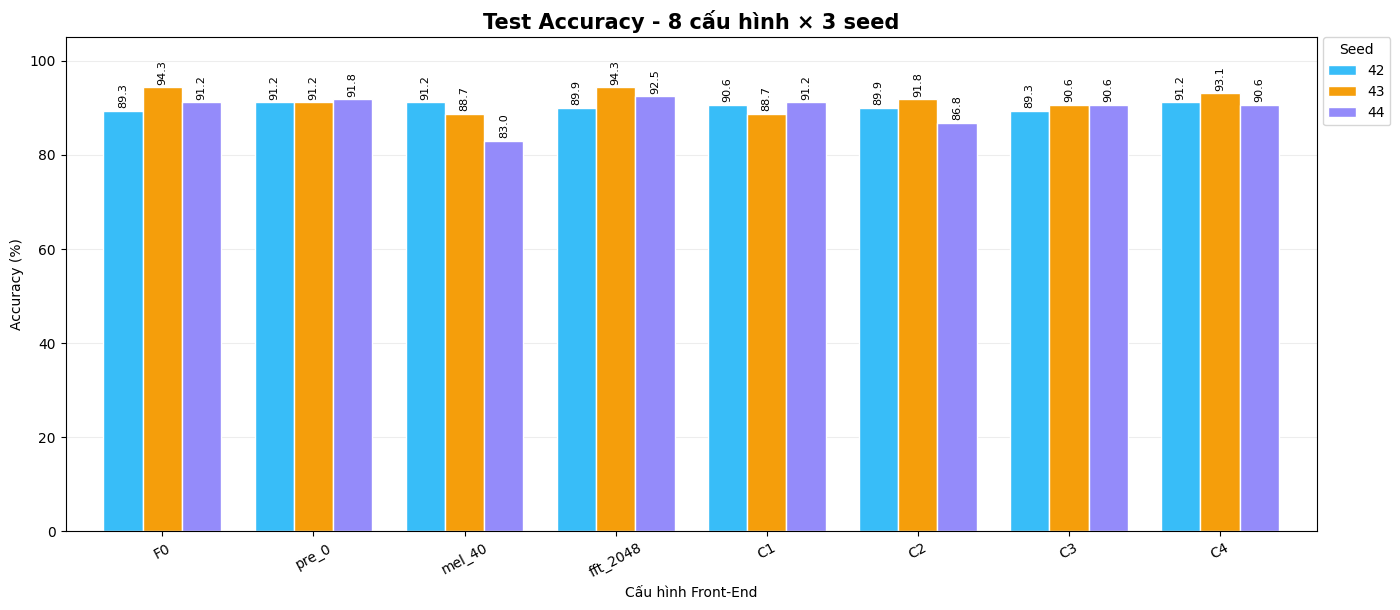

Ma trận C: 8 cấu hình × 3 seed = 24 checkpoint FP32; nếu mỗi checkpoint áp dụng đủ 3 phương pháp lượng tử thì có 72 phiên bản lượng tử, gồm:
PTQ INT8 ; PTQ INT16x8 ; QAT INT8


In [8]:
# Đọc duy nhất 24 kết quả C từ results/test_summary.csv.
canonical_test=archived_summary[archived_summary.trial_id.isin(registry.trial_id)].copy()
rows=[]
for r in registry.itertuples():
    hit=canonical_test[canonical_test.trial_id==r.trial_id]
    if len(hit)!=1:raise RuntimeError(f'{r.trial_id}: cần đúng một dòng trong results/test_summary.csv')
    t=hit.iloc[0]
    rows.append({'trial_id':r.trial_id,'cau_hinh':r.cau_hinh,'seed':r.seed,
       'Test_source':'PIPELINE test_summary.csv',
       'accuracy':float(t['accuracy']),'macro_f1':float(t['macro_f1']),
       'asthma_recall':float(t['asthma_recall']),'asthma_fn':float(t['asthma_fn']),
       'non_asthma_fp':float(t['non_asthma_fp'])})
TEST=pd.DataFrame(rows)
print(f'Test pipeline: {TEST.accuracy.notna().sum()}/24 checkpoint')
test_accuracy_pct = (
    TEST.pivot(index='cau_hinh', columns='seed', values='accuracy')
        .reindex(EXPECTED)
        .mul(100)
)
display(test_accuracy_pct.round(2))

# Biểu đồ cột Test đặt ngay dưới bảng, đồng nhất cách đọc với Validation.
fig, ax = plt.subplots(figsize=(15, 6.2), facecolor='white')
colors = ['#38bdf8', '#f59e0b', "#948bfa"]
test_accuracy_pct.plot(
    kind='bar', ax=ax, width=0.78, color=colors, edgecolor='white'
)
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=2, fontsize=8, rotation=90)
ax.set_title('Test Accuracy - 8 cấu hình × 3 seed', fontsize=15, fontweight='bold')
ax.set_xlabel('Cấu hình Front-End')
ax.set_ylabel('Accuracy (%)')
ax.set_ylim(0, 105)
ax.tick_params(axis='x', rotation=28)
ax.legend(
    title='Seed', ncol=1, loc='upper left',
    bbox_to_anchor=(1.005, 1.0), borderaxespad=0.0, frameon=True
)
ax.grid(axis='y', alpha=0.22)
ax.set_axisbelow(True)
fig.tight_layout(rect=(0, 0, 0.94, 1))
plt.show()

print("Ma trận C: 8 cấu hình × 3 seed = 24 checkpoint FP32; nếu mỗi checkpoint áp dụng đủ 3 phương pháp lượng tử thì có 72 phiên bản lượng tử, gồm:")
print("PTQ INT8 ; PTQ INT16x8 ; QAT INT8")

## 5. Tổng hợp Validation ↔ Test, Mean ± SD và paired errors

Bảng này tách rõ **Validation (chọn / phân tích)** và **Test lịch sử (mô tả, không được dùng để tái chọn best model độc lập)**. Các ô chưa đo sẽ để trống, không dùng placeholder số liệu. Khi đủ 24 trial, xem hiệu ứng ba yếu tố và đánh đổi bộ nhớ mô hình/FFT ở phần kết luận.

,val_n,Val Mean %,Val SD pp,test_n,Test Mean %,Test SD pp,Gap Test-Val pp,Params (theory V1)
cau_hinh,,,,,,,,
F0,3,97.19,2.93,3,91.61,2.54,-5.57,527994
pre_0,3,97.19,1.87,3,91.40,0.36,-5.78,527994
mel_40,3,96.54,1.35,3,87.63,4.19,-8.91,331386
fft_2048,3,96.97,0.37,3,92.24,2.21,-4.73,527994
C1,3,98.27,1.35,3,90.15,1.31,-8.12,331386
C2,3,97.40,0.65,3,89.52,2.54,-7.88,527994
C3,3,97.19,0.99,3,90.15,0.73,-7.04,331386
C4,3,98.05,0.65,3,91.61,1.31,-6.44,331386


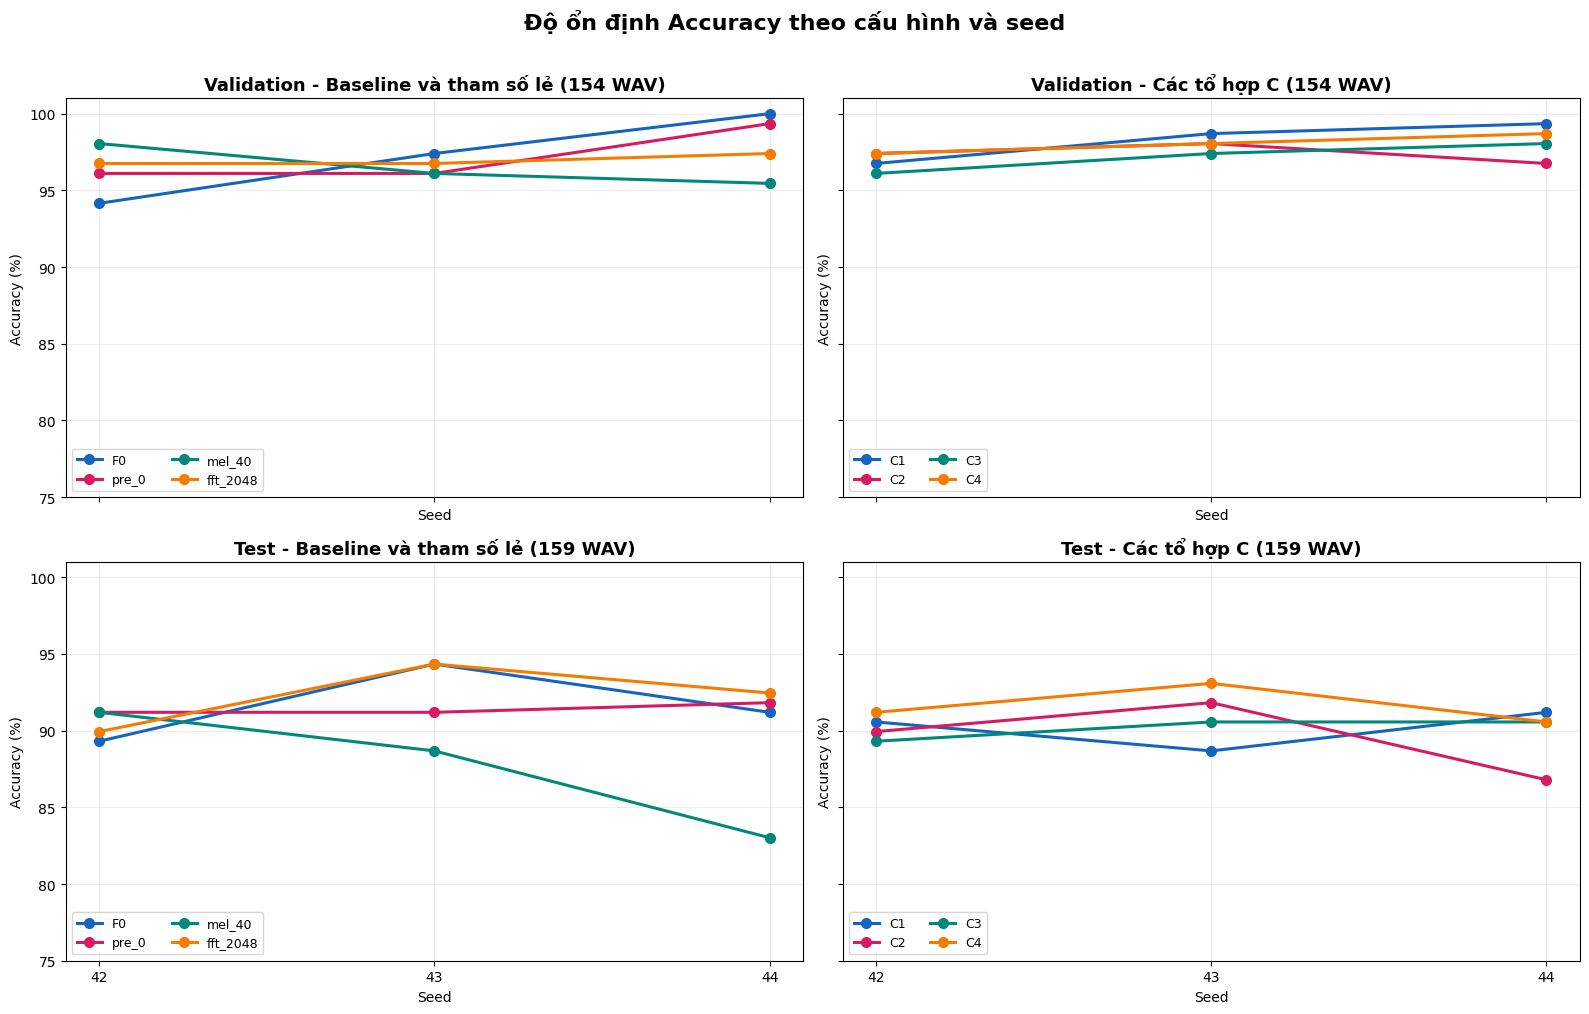

In [9]:
val_stats=VAL.groupby('cau_hinh').agg(val_n=('accuracy','count'),val_mean=('accuracy','mean'),val_sd=('accuracy','std'),val_fn=('asthma_fn','sum'))
test_stats=TEST.groupby('cau_hinh').agg(test_n=('accuracy','count'),test_mean=('accuracy','mean'),test_sd=('accuracy','std'),test_fn=('asthma_fn','sum'))
comp=val_stats.join(test_stats).reindex(EXPECTED)
comp['Val Mean %']=(100*comp.val_mean).round(2)
comp['Val SD pp']=(100*comp.val_sd).round(2)
comp['Test Mean %']=(100*comp.test_mean).round(2)
comp['Test SD pp']=(100*comp.test_sd).round(2)
comp['Gap Test-Val pp']=(100*(comp.test_mean-comp.val_mean)).round(2)
comp['Params (theory V1)']=comp.index.map(lambda k: 331386 if EXPECTED[k][1]==40 else 527994)
display(comp[['val_n','Val Mean %','Val SD pp','test_n','Test Mean %','Test SD pp','Gap Test-Val pp','Params (theory V1)']])

# Tách cấu hình lẻ và combo C để đường biểu diễn không chồng lấn.
SINGLE_CONFIGS = ('F0', 'pre_0', 'mel_40', 'fft_2048')
COMBO_CONFIGS = ('C1', 'C2', 'C3', 'C4')
GROUP_COLORS = ('#1565C0', '#D81B60', '#00897B', '#F57C00')

def plot_accuracy_group(ax, frame, configs, title):
    plotted = 0
    for config, color in zip(configs, GROUP_COLORS):
        rows = frame[frame.cau_hinh.eq(config)].sort_values('seed')
        if rows.accuracy.notna().any():
            ax.plot(
                rows.seed, 100 * rows.accuracy,
                marker='o', markersize=7, linewidth=2.2,
                color=color, label=config,
            )
            plotted += 1
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_xlabel('Seed')
    ax.set_ylabel('Accuracy (%)')
    ax.set_xticks(SEEDS)
    ax.set_ylim(75, 101)
    ax.grid(alpha=.22)
    if plotted:
        ax.legend(fontsize=9, loc='lower left', ncol=2)

# Một figure 2×2: Validation ở hàng trên, Test ở hàng dưới.
fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharex=True, sharey=True)
plot_accuracy_group(
    axes[0, 0], VAL, SINGLE_CONFIGS,
    'Validation - Baseline và tham số lẻ (154 WAV)',
)
plot_accuracy_group(
    axes[0, 1], VAL, COMBO_CONFIGS,
    'Validation - Các tổ hợp C (154 WAV)',
)
plot_accuracy_group(
    axes[1, 0], TEST, SINGLE_CONFIGS,
    'Test - Baseline và tham số lẻ (159 WAV)',
)
plot_accuracy_group(
    axes[1, 1], TEST, COMBO_CONFIGS,
    'Test - Các tổ hợp C (159 WAV)',
)
fig.suptitle('Độ ổn định Accuracy theo cấu hình và seed', fontsize=16, fontweight='bold', y=1.01)
fig.tight_layout()
plt.show()

In [10]:
# Đối chiếu cặp Test ở cùng seed (khi có prediction-level). Không ghép theo vị trí hàng.
all_pred=[]; missing_test_predictions=[]
for r in registry.itertuples():
    pred=csv_to_table(r.trial_id,'test')
    if pred is None:missing_test_predictions.append(r.trial_id)
    else:all_pred.append(pred)
if missing_test_predictions:
    print('Thiếu prediction-level của',len(missing_test_predictions),'trial; vẫn dùng test_summary.csv cho metric tổng hợp.')
if all_pred:
    P=pd.concat(all_pred,ignore_index=True)
    P['file']=P.file.astype(str).str.replace('\\','/',regex=False)
    if P.duplicated(['trial_id','file']).any():raise RuntimeError('Prediction duplicate (trial,file)')
    pair=[]
    for name in EXPECTED:
        if name=='F0':continue
        for seed in SEEDS:
            alt=f'{VARIANT_IDS[name]}__V1__s{seed}'
            base=f'{VARIANT_IDS["F0"]}__V1__s{seed}'
            a=P[P.trial_id==alt].set_index('file')
            b=P[P.trial_id==base].set_index('file')
            if len(a)==N_TEST and len(b)==N_TEST:
                if set(a.index)!=set(b.index):raise RuntimeError(f'Mismatch WAV set: {alt} vs {base}')
                jj=a[['true_label','predicted_label']].join(b[['true_label','predicted_label']],lsuffix='_alt',rsuffix='_F0')
                if not jj.true_label_alt.eq(jj.true_label_F0).all():raise RuntimeError('Label mismatch')
                ac=jj.true_label_alt.eq(jj.predicted_label_alt)
                bc=jj.true_label_F0.eq(jj.predicted_label_F0)
                pair.append({'cau_hinh':name,'seed':seed,'alt_dung_F0_sai':int((ac&~bc).sum()),
                             'alt_sai_F0_dung':int((~ac&bc).sum()),
                             'chenh_Accuracy_WAV':int(ac.sum()-bc.sum())})
    display(pd.DataFrame(pair).sort_values(['cau_hinh','seed']) if pair else 'Chưa đủ prediction-level Test để ghép cặp.')
else:
    print('Chưa có prediction-level Test của 24 checkpoint.')

,cau_hinh,seed,alt_dung_F0_sai,alt_sai_F0_dung,chenh_Accuracy_WAV
9,C1,42,5,3,2
10,C1,43,0,9,-9
11,C1,44,3,3,0
12,C2,42,6,5,1
13,C2,43,0,4,-4
14,C2,44,2,9,-7
15,C3,42,5,5,0
16,C3,43,0,6,-6
17,C3,44,4,5,-1
18,C4,42,7,4,3


In [11]:
print('Nguồn Validation duy nhất:', VAL_SUMMARY_PATH)
print('Nguồn Test duy nhất      :', TEST_SUMMARY_PATH)
print('Notebook không tạo summary_val_8x3.csv hoặc summary_test_8x3.csv.')
print('READY FOR D ?', bool(VAL.accuracy.notna().all() and TEST.accuracy.notna().all()))

Nguồn Validation duy nhất: D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchmarking\Patient_Node\Frontend_Benchmarking\results\val_summary.csv
Nguồn Test duy nhất      : D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchmarking\Patient_Node\Frontend_Benchmarking\results\test_summary.csv
Notebook không tạo summary_val_8x3.csv hoặc summary_test_8x3.csv.
READY FOR D ? True


## 6. Kết luận lựa chọn Front-End C4/s44 và chuyển sang lượng tử hóa

Qua khảo sát **8 tổ hợp Front-End trên 3 seed (42–44)** với kiến trúc V1 cố định, cấu hình **C4 (`pre=0`, `Mel40`, `FFT2048`)** được ưu tiên nhờ sự cân bằng giữa chất lượng phân loại, độ biến thiên kết quả và độ phức tạp mô hình.

Cụ thể, C4 đạt **Validation Accuracy trung bình 98,05% ± 0,65 điểm phần trăm**, cao hơn cấu hình C3 có cùng Mel/FFT nhưng sử dụng pre-emphasis (97,19% ± 0,99 pp). Mặc dù C1 đạt Accuracy trung bình nhỉnh hơn (98,27%), độ lệch chuẩn của C1 lại cao hơn (1,35 pp). Điều này cho thấy C4 duy trì hiệu năng Validation tương đối cao và nhất quán hơn trong phạm vi ba seed khảo sát. Trên Test FP32, C4 đạt Accuracy trung bình **91,61% ± 1,31 pp**, cho thấy cấu hình này có chất lượng phân loại cạnh tranh nhưng không phải phương án dẫn đầu tuyệt đối ở mọi chỉ số.

Bên cạnh đó, việc sử dụng **Mel40 thay cho Mel64** giúp giảm số tham số của V1 từ 527.994 xuống **331.386 (khoảng 37,2%)**. Việc loại bỏ pre-emphasis cũng giản lược một bước tiền xử lý, dù FFT2048 vẫn đòi hỏi chi phí DSP lớn hơn FFT1024.

Trong ba checkpoint C4, **seed 44 đạt Validation Accuracy cao nhất (98,701%)**, so với 97,403% ở s42 và 98,052% ở s43. Do đó, **V1/C4/s44 được lựa chọn làm checkpoint FP32 tham chiếu**, thay vì lựa chọn theo Test Accuracy cao nhất; thực tế Test Accuracy của s44 là 90,566%, thấp hơn s43 (93,082%).

**Từ các kết quả trên, nghiên cứu ưu tiên cấu hình C4/s44 để chuyển sang notebook D — Quantization**, tiếp tục đánh giá PTQ INT8, QAT INT8 và PTQ INT16x8. Quyết định này là lựa chọn trong phạm vi khảo sát Front-End, chưa khẳng định C4 tối ưu tuyệt đối hoặc phương pháp lượng tử hóa phù hợp nhất trước khi có kết quả kiểm chứng tiếp theo.